# Wet AMD Lesion Segmentation — Model 3: Multi-Scale Cross-Branch Skip-Connected U-Net

**Architecture Strategy (Idea 2 - Multi-Scale Cross-Branch Skip Fusion):**
* **Shared Contracting Encoder:** Standard 5-stage feature hierarchy ($512 \to 256 \to 128 \to 64 \to 32$) with bottleneck processing.
* **Auxiliary Binary Decoder:** Learns foreground lesion boundary features across all four decoder stages ($32 \to 64 \to 128 \to 256 \to 512$).
* **Cross-Branch Skip Fusion:** At each resolution stage ($d_1, d_2, d_3, d_4$), feature representations from the binary branch are projected via $1 \times 1$ convolutions and added directly into the multi-class decoder blocks. This provides explicit gradient pathways and reinforces lesion localization across all spatial scales.
* **Multi-Task Optimization:** Supervised using a joint hybrid objective ($\mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$) with gradient accumulation, `PolyLRScheduler`, and `GlobalMetricTracker` to maintain parity with the baseline benchmark setup.

In [1]:
import os
import gc
import csv
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Hardware & memory environment variables
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def cleanup_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

seed_everything(42)
cleanup_memory()

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")

Active Compute Device: mps


## 1. Dataset Pipeline & Target Generation
Loads pre-sliced OCT B-scans and categorical ground-truth masks from `processed_data/`, applies data augmentations, and prepares synchronized multi-class and binary targets.

In [2]:
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDatasetModel3(Dataset):
    def __init__(self, data_root="processed_data", split="train", target_size=(512, 512), augment=True):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size
        self.split = split
        self.augment = augment and (split == "train")

        if not os.path.exists(self.inputs_dir):
            raise FileNotFoundError(f"Missing directory: {self.inputs_dir}. Please run dataset preprocessing first.")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def _apply_augmentations(self, img, mask):
        if random.random() > 0.5:
            img = cv2.flip(img, 1)
            mask = cv2.flip(mask, 1)

        angle = random.uniform(-10.0, 10.0)
        h, w = img.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
        return img, mask

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        if img is None or mask_bgr is None:
            raise ValueError(f"Corrupt pair at: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        if self.augment:
            img, mask_labels = self._apply_augmentations(img, mask_labels)

        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()
        bin_tensor = (mask_tensor > 0).float().unsqueeze(0)

        return img_tensor, mask_tensor, bin_tensor

DATA_DIR = "processed_data"
MICRO_BATCH_SIZE = 2 if device.type == "mps" else 8
ACCUM_STEPS = 4 if device.type == "mps" else 1
VAL_BATCH_SIZE = 2 if device.type == "mps" else 8
NUM_WORKERS = 0 if device.type == "mps" else 4

train_dataset = AMDDatasetModel3(DATA_DIR, split="train", target_size=(512, 512), augment=True)
val_dataset = AMDDatasetModel3(DATA_DIR, split="val", target_size=(512, 512), augment=False)

train_loader = DataLoader(train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=VAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

print(f"Loaded {len(train_dataset)} train samples and {len(val_dataset)} validation samples.")

Loaded 2346 train samples and 703 validation samples.


## 2. Model 3 Architecture Definition: Cross-Branch Skip Fusion
Defines the dual-decoder architecture with cross-branch skip connections routing features from the auxiliary binary branch into the multi-class branch at every resolution stage.

In [3]:
class DoubleConv(nn.Module):
    """[Conv2d -> BatchNorm -> ReLU] * 2"""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class CrossSkipFusionBlock(nn.Module):
    """Projects and fuses multi-scale binary decoder representations into the multi-class decoder."""
    def __init__(self, bin_channels: int, mc_channels: int):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Conv2d(bin_channels, mc_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(mc_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, mc_feat: torch.Tensor, bin_feat: torch.Tensor) -> torch.Tensor:
        return mc_feat + self.proj(bin_feat)


class Model3CrossSkipUNet(nn.Module):
    def __init__(self, in_channels: int = 1, num_classes: int = 6, base_channels: int = 32):
        super().__init__()
        c = base_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 1. Shared Contracting Encoder
        self.inc = DoubleConv(in_channels, c)           # 1 -> 32
        self.down1 = DoubleConv(c, c * 2)              # 32 -> 64
        self.down2 = DoubleConv(c * 2, c * 4)          # 64 -> 128
        self.down3 = DoubleConv(c * 4, c * 8)          # 128 -> 256
        self.bottleneck = DoubleConv(c * 8, c * 16)    # 256 -> 512

        # 2. Binary Decoder Branch
        self.bin_up1 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.bin_conv1 = DoubleConv(c * 16, c * 8)

        self.bin_up2 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.bin_conv2 = DoubleConv(c * 8, c * 4)

        self.bin_up3 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.bin_conv3 = DoubleConv(c * 4, c * 2)

        self.bin_up4 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.bin_conv4 = DoubleConv(c * 2, c)
        self.bin_head = nn.Conv2d(c, 1, kernel_size=1)

        # 3. Cross-Branch Skip Fusion Modules (Idea 2)
        self.cross_fuse1 = CrossSkipFusionBlock(bin_channels=c * 8, mc_channels=c * 8)
        self.cross_fuse2 = CrossSkipFusionBlock(bin_channels=c * 4, mc_channels=c * 4)
        self.cross_fuse3 = CrossSkipFusionBlock(bin_channels=c * 2, mc_channels=c * 2)
        self.cross_fuse4 = CrossSkipFusionBlock(bin_channels=c, mc_channels=c)

        # 4. Multi-Class Decoder Branch
        self.mc_up1 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.mc_conv1 = DoubleConv(c * 16, c * 8)

        self.mc_up2 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.mc_conv2 = DoubleConv(c * 8, c * 4)

        self.mc_up3 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.mc_conv3 = DoubleConv(c * 4, c * 2)

        self.mc_up4 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.mc_conv4 = DoubleConv(c * 2, c)
        self.mc_head = nn.Conv2d(c, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor):
        x1 = self.inc(x)
        x2 = self.down1(self.pool(x1))
        x3 = self.down2(self.pool(x2))
        x4 = self.down3(self.pool(x3))
        b = self.bottleneck(self.pool(x4))

        # Binary Decoder
        bin_d1 = self.bin_conv1(torch.cat([x4, self.bin_up1(b)], dim=1))
        bin_d2 = self.bin_conv2(torch.cat([x3, self.bin_up2(bin_d1)], dim=1))
        bin_d3 = self.bin_conv3(torch.cat([x2, self.bin_up3(bin_d2)], dim=1))
        bin_d4 = self.bin_conv4(torch.cat([x1, self.bin_up4(bin_d3)], dim=1))
        bin_logits = self.bin_head(bin_d4)

        # Multi-Class Decoder with Cross-Branch Skip Connections
        mc_d1 = self.mc_conv1(torch.cat([x4, self.mc_up1(b)], dim=1))
        mc_d1 = self.cross_fuse1(mc_d1, bin_d1)

        mc_d2 = self.mc_conv2(torch.cat([x3, self.mc_up2(mc_d1)], dim=1))
        mc_d2 = self.cross_fuse2(mc_d2, bin_d2)

        mc_d3 = self.mc_conv3(torch.cat([x2, self.mc_up3(mc_d2)], dim=1))
        mc_d3 = self.cross_fuse3(mc_d3, bin_d3)

        mc_d4 = self.mc_conv4(torch.cat([x1, self.mc_up4(mc_d3)], dim=1))
        mc_d4 = self.cross_fuse4(mc_d4, bin_d4)

        mc_logits = self.mc_head(mc_d4)

        return mc_logits, bin_logits

# Architecture dimension validation
test_net = Model3CrossSkipUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
dummy_in = torch.randn(2, 1, 512, 512, device=device)
with torch.no_grad():
    test_mc, test_bin = test_net(dummy_in)

total_params = sum(p.numel() for p in test_net.parameters() if p.requires_grad)
print(f"Model 3 Parameters: {total_params:,}")
print(f"Multi-Class Logits Shape: {tuple(test_mc.shape)}")
print(f"Binary Logits Shape:      {tuple(test_bin.shape)}")
assert test_mc.shape == (2, 6, 512, 512) and test_bin.shape == (2, 1, 512, 512)
del test_net, dummy_in, test_mc, test_bin
cleanup_memory()

Model 3 Parameters: 10,899,463
Multi-Class Logits Shape: (2, 6, 512, 512)
Binary Logits Shape:      (2, 1, 512, 512)


## 3. Multi-Task Objective, Global Metric Accumulation, and Learning Rate Schedule
Implements the multi-task loss ($\mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$), `GlobalMetricTracker` across all 703 validation scans, and the polynomial learning rate scheduler.

In [4]:
class MultiTaskLoss(nn.Module):
    def __init__(self, num_classes: int = 6, ignore_index: int = 255, binary_weight: float = 0.5,
                 ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.binary_weight = binary_weight
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)

    def forward(self, mc_logits: torch.Tensor, bin_logits: torch.Tensor,
                targets: torch.Tensor, bin_targets: torch.Tensor):
        # 1. Multi-Class Loss
        ce_loss = self.ce(mc_logits, targets)
        probs = F.softmax(mc_logits, dim=1)
        valid_mask = (targets != self.ignore_index)

        targets_clean = targets.clone()
        targets_clean[~valid_mask] = 0
        targets_one_hot = F.one_hot(targets_clean, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        for c in range(1, self.num_classes):
            p = probs[:, c, ...][valid_mask]
            t = targets_one_hot[:, c, ...][valid_mask]
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)

        mc_dice_loss = dice_total / (self.num_classes - 1)
        l_mc = (self.ce_weight * ce_loss) + (self.dice_weight * mc_dice_loss)

        # 2. Binary Detection Loss
        valid_mask_bin = valid_mask.unsqueeze(1)
        b_logits_valid = bin_logits[valid_mask_bin]
        b_targets_valid = bin_targets[valid_mask_bin]

        bce_loss = F.binary_cross_entropy_with_logits(b_logits_valid, b_targets_valid)
        b_probs = torch.sigmoid(b_logits_valid)
        b_intersection = (b_probs * b_targets_valid).sum()
        b_dice = (2.0 * b_intersection + self.smooth) / (b_probs.sum() + b_targets_valid.sum() + self.smooth)
        b_dice_loss = 1.0 - b_dice

        l_bin = (0.5 * bce_loss) + (0.5 * b_dice_loss)

        total_loss = l_mc + (self.binary_weight * l_bin)
        return total_loss, l_mc, l_bin


class GlobalMetricTracker:
    def __init__(self, num_classes: int = 6):
        self.num_classes = num_classes
        self.class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
        self.reset()

    def reset(self):
        self.intersections = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_preds = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_targets = {c: 0.0 for c in range(1, self.num_classes)}

    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        for c in range(1, self.num_classes):
            p = (preds == c).float()
            t = (targets == c).float()
            self.intersections[c] += (p * t).sum().item()
            self.total_preds[c] += p.sum().item()
            self.total_targets[c] += t.sum().item()

    def compute(self):
        dice_scores, iou_scores = {}, {}
        for c, name in self.class_map.items():
            inter = self.intersections[c]
            p_sum = self.total_preds[c]
            t_sum = self.total_targets[c]
            union = p_sum + t_sum - inter

            dice = (2.0 * inter) / (p_sum + t_sum + 1e-8) * 100.0
            iou = inter / (union + 1e-8) * 100.0
            dice_scores[name] = dice
            iou_scores[name] = iou

        mean_dice = sum(dice_scores.values()) / len(dice_scores)
        mean_iou = sum(iou_scores.values()) / len(iou_scores)
        return dice_scores, iou_scores, mean_dice, mean_iou


class PolyLRScheduler(torch.optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, max_epochs, power=0.9, min_lr=1e-6, last_epoch=-1):
        self.max_epochs = max_epochs
        self.power = power
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        factor = (1.0 - self.last_epoch / max(1, self.max_epochs)) ** self.power
        return [max(self.min_lr, base_lr * factor) for base_lr in self.base_lrs]

## 4. Supervised Training Loop & Checkpointing
Trains Model 3 for 20 epochs using AdamW, gradient accumulation, and saves optimal weights to `best_unet_model3.pth`.

In [5]:
def run_model3_training():
    cleanup_memory()
    seed_everything(42)

    EPOCHS = 40
    LEARNING_RATE = 1e-4
    NUM_CLASSES = 6
    LOG_FILE = "model3_training_log.csv"
    CHECKPOINT_FILE = "best_unet_model3.pth"

    model = Model3CrossSkipUNet(in_channels=1, num_classes=NUM_CLASSES, base_channels=32).to(device)
    criterion = MultiTaskLoss(num_classes=NUM_CLASSES, ignore_index=255, binary_weight=0.5,
                              ce_weight=0.5, dice_weight=0.5, smooth=1.0).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = PolyLRScheduler(optimizer, max_epochs=EPOCHS, power=0.9, min_lr=1e-6)

    fieldnames = [
        "epoch", "train_loss", "val_loss", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

    best_mean_dice = 0.0

    print("Beginning Model 3 Training (Dual-Decoder Cross-Branch Skip Fusion)...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss_accum = 0.0
        optimizer.zero_grad(set_to_none=True)

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]")
        for step, (images, mc_targets, bin_targets) in enumerate(pbar):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            bin_targets = bin_targets.to(device, dtype=torch.float32)

            mc_logits, bin_logits = model(images)
            loss, l_mc, l_bin = criterion(mc_logits, bin_logits, mc_targets, bin_targets)

            loss_scaled = loss / ACCUM_STEPS
            loss_scaled.backward()

            if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            train_loss_accum += loss.item()
            pbar.set_postfix({"tot": f"{loss.item():.4f}", "mc": f"{l_mc.item():.3f}", "bin": f"{l_bin.item():.3f}"})

        scheduler.step()
        epoch_train_loss = train_loss_accum / len(train_loader)

        # Validation Phase
        model.eval()
        val_loss_accum = 0.0
        metric_tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)

        with torch.no_grad():
            for images, mc_targets, bin_targets in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]"):
                images = images.to(device)
                mc_targets = mc_targets.to(device, dtype=torch.long)
                bin_targets = bin_targets.to(device, dtype=torch.float32)

                mc_logits, bin_logits = model(images)
                loss, _, _ = criterion(mc_logits, bin_logits, mc_targets, bin_targets)
                val_loss_accum += loss.item()

                preds = torch.argmax(mc_logits, dim=1)
                metric_tracker.update(preds, mc_targets)

        epoch_val_loss = val_loss_accum / len(val_loader)
        avg_dice, avg_iou, mean_dice, mean_iou = metric_tracker.compute()

        print(f"\n--- Epoch {epoch:02d} Summary (Model 3) ---")
        print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        print(f"Mean Dice:  {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Per-Class Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%")

        log_entry = {
            "epoch": epoch,
            "train_loss": f"{epoch_train_loss:.4f}",
            "val_loss": f"{epoch_val_loss:.4f}",
            "mean_dice": f"{mean_dice:.2f}",
            "mean_iou": f"{mean_iou:.2f}",
            "SRF_dice": f"{avg_dice['SRF']:.2f}",
            "IRF_dice": f"{avg_dice['IRF']:.2f}",
            "PED_dice": f"{avg_dice['PED']:.2f}",
            "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
            "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
            "SRF_iou": f"{avg_iou['SRF']:.2f}",
            "IRF_iou": f"{avg_iou['IRF']:.2f}",
            "PED_iou": f"{avg_iou['PED']:.2f}",
            "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
            "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
        }
        with open(LOG_FILE, "a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writerow(log_entry)

        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            torch.save(model.state_dict(), CHECKPOINT_FILE)
            print(f"--> Saved optimal Model 3 checkpoint with Mean Dice: {best_mean_dice:.2f}%")

        cleanup_memory()

    print(f"\nModel 3 Training Complete. Peak Validation Mean Dice: {best_mean_dice:.2f}%")

run_model3_training()

Beginning Model 3 Training (Dual-Decoder Cross-Branch Skip Fusion)...


Epoch 01/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:29<00:00,  3.92it/s]



--- Epoch 01 Summary (Model 3) ---
Train Loss: 1.0463 | Val Loss: 0.8752
Mean Dice:  52.95% | Mean IoU: 40.14%
Per-Class Dice -> SRF: 71.69% | IRF: 0.00% | PED: 53.59% | SHRM: 61.82% | IS/OS: 77.67%
--> Saved optimal Model 3 checkpoint with Mean Dice: 52.95%


Epoch 02/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:29<00:00,  3.94it/s]



--- Epoch 02 Summary (Model 3) ---
Train Loss: 0.7741 | Val Loss: 0.7472
Mean Dice:  62.93% | Mean IoU: 47.39%
Per-Class Dice -> SRF: 78.03% | IRF: 36.71% | PED: 61.46% | SHRM: 65.19% | IS/OS: 73.23%
--> Saved optimal Model 3 checkpoint with Mean Dice: 62.93%


...


--- Epoch 38 Summary (Model 3) ---
Train Loss: 0.1537 | Val Loss: 0.2635
Mean Dice:  78.47% | Mean IoU: 64.75%
Per-Class Dice -> SRF: 79.08% | IRF: 79.14% | PED: 78.19% | SHRM: 71.77% | IS/OS: 84.19%


Epoch 39/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:28<00:00,  3.97it/s]



--- Epoch 39 Summary (Model 3) ---
Train Loss: 0.1523 | Val Loss: 0.2655
Mean Dice:  77.93% | Mean IoU: 64.02%
Per-Class Dice -> SRF: 78.04% | IRF: 78.33% | PED: 78.10% | SHRM: 71.03% | IS/OS: 84.14%


Epoch 40/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:28<00:00,  3.97it/s]



--- Epoch 40 Summary (Model 3) ---
Train Loss: 0.1504 | Val Loss: 0.2675
Mean Dice:  78.03% | Mean IoU: 64.15%
Per-Class Dice -> SRF: 78.40% | IRF: 77.83% | PED: 78.45% | SHRM: 71.45% | IS/OS: 84.03%

Model 3 Training Complete. Peak Validation Mean Dice: 78.49%


## 5. Quantitative Model 3 Benchmark Evaluation Report
Evaluates `best_unet_model3.pth` against the 703 validation scans and produces a direct comparison table and visual bar plot against the AMD-SD Table 3 baseline metrics.

Loading Model 3 checkpoint: 'best_unet_model3.pth'...


Evaluating Model 3 Benchmark: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:22<00:00,  4.24it/s]



            WET AMD LESION SEGMENTATION: MODEL 3 BENCHMARK REPORT
    Biomarker / Class Paper Baseline Dice (%) Model 3 Dice (%) Dice Delta Paper Baseline IoU (%) Model 3 IoU (%) IoU Delta
                  SRF                  78.65%           78.52%     -0.13%                 64.81%          64.64%    -0.17%
                  IRF                  78.66%           80.34%     +1.68%                 64.82%          67.14%    +2.32%
                  PED                  79.62%           78.12%     -1.50%                 66.14%          64.10%    -2.04%
                 SHRM                  72.10%           71.37%     -0.73%                 56.37%          55.49%    -0.88%
                IS/OS                  83.76%           84.10%     +0.34%                 72.06%          72.57%    +0.51%
Mean (All Biomarkers)                  78.40%           78.49%     +0.09%                 64.48%          64.79%    +0.31%

Saved report to 'model3_benchmark_report.csv'.


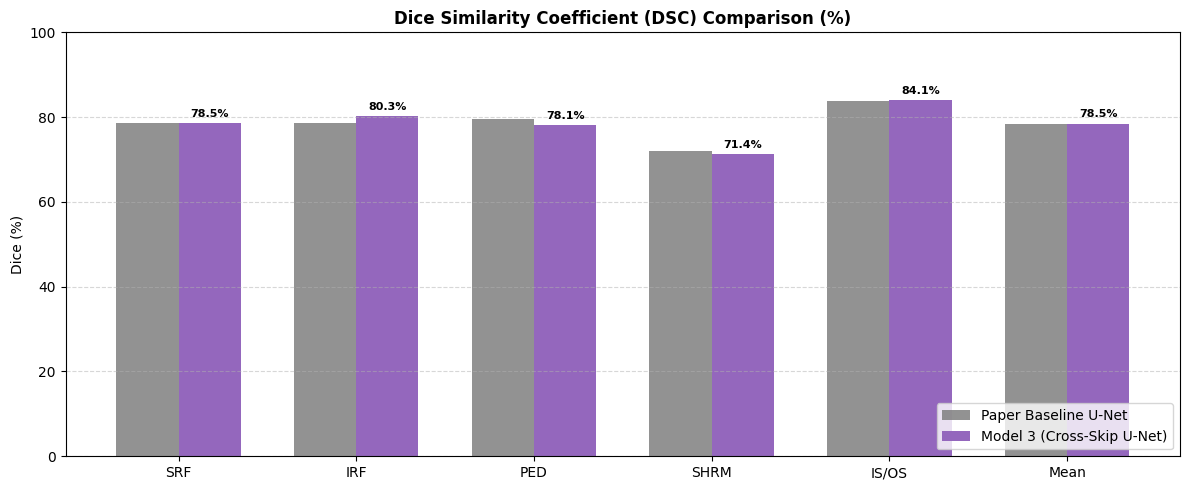

In [6]:
def run_model3_benchmark():
    cleanup_memory()
    CKPT_PATH = "best_unet_model3.pth"
    print(f"Loading Model 3 checkpoint: '{CKPT_PATH}'...")

    eval_model = Model3CrossSkipUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    if not os.path.exists(CKPT_PATH):
        raise FileNotFoundError(f"Checkpoint not found at '{CKPT_PATH}'. Train the model first.")

    eval_model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    eval_model.eval()

    metric_tracker = GlobalMetricTracker(num_classes=6)

    with torch.no_grad():
        for images, mc_targets, _ in tqdm(val_loader, desc="Evaluating Model 3 Benchmark"):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)

            mc_logits, _ = eval_model(images)
            preds = torch.argmax(mc_logits, dim=1)
            metric_tracker.update(preds, mc_targets)

    m3_dice, m3_iou, m3_mean_dice, m3_mean_iou = metric_tracker.compute()

    paper_baseline_dice = {
        "SRF": 78.65, "IRF": 78.66, "PED": 79.62, "SHRM": 72.10, "IS/OS": 83.76, "Mean": 78.40
    }
    paper_baseline_iou = {
        "SRF": 64.81, "IRF": 64.82, "PED": 66.14, "SHRM": 56.37, "IS/OS": 72.06, "Mean": 64.48
    }

    biomarkers = ["SRF", "IRF", "PED", "SHRM", "IS/OS"]
    report_rows = []

    for b in biomarkers:
        report_rows.append({
            "Biomarker / Class": b,
            "Paper Baseline Dice (%)": f"{paper_baseline_dice[b]:.2f}%",
            "Model 3 Dice (%)": f"{m3_dice[b]:.2f}%",
            "Dice Delta": f"{m3_dice[b] - paper_baseline_dice[b]:+.2f}%",
            "Paper Baseline IoU (%)": f"{paper_baseline_iou[b]:.2f}%",
            "Model 3 IoU (%)": f"{m3_iou[b]:.2f}%",
            "IoU Delta": f"{m3_iou[b] - paper_baseline_iou[b]:+.2f}%"
        })

    report_rows.append({
        "Biomarker / Class": "Mean (All Biomarkers)",
        "Paper Baseline Dice (%)": f"{paper_baseline_dice['Mean']:.2f}%",
        "Model 3 Dice (%)": f"{m3_mean_dice:.2f}%",
        "Dice Delta": f"{m3_mean_dice - paper_baseline_dice['Mean']:+.2f}%",
        "Paper Baseline IoU (%)": f"{paper_baseline_iou['Mean']:.2f}%",
        "Model 3 IoU (%)": f"{m3_mean_iou:.2f}%",
        "IoU Delta": f"{m3_mean_iou - paper_baseline_iou['Mean']:+.2f}%"
    })

    benchmark_df = pd.DataFrame(report_rows)
    print("\n" + "="*85)
    print("            WET AMD LESION SEGMENTATION: MODEL 3 BENCHMARK REPORT")
    print("="*85)
    print(benchmark_df.to_string(index=False))

    benchmark_df.to_csv("model3_benchmark_report.csv", index=False)
    print("\nSaved report to 'model3_benchmark_report.csv'.")

    # Plot Visual Bar Chart
    plot_categories = biomarkers + ["Mean"]
    x = np.arange(len(plot_categories))
    width = 0.35

    m3_dices = [m3_dice[b] for b in biomarkers] + [m3_mean_dice]
    paper_dices = [paper_baseline_dice[b] for b in plot_categories]

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(x - width/2, paper_dices, width, label='Paper Baseline U-Net', color='#7f7f7f', alpha=0.85)
    rects = ax.bar(x + width/2, m3_dices, width, label='Model 3 (Cross-Skip U-Net)', color='#9467bd')
    ax.set_title('Dice Similarity Coefficient (DSC) Comparison (%)', fontweight='bold')
    ax.set_ylabel('Dice (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(plot_categories)
    ax.set_ylim(0, 100)
    ax.legend(loc='lower right')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    for bar in rects:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

    plt.tight_layout()
    plt.show()

run_model3_benchmark()

## 6. Qualitative Visualizations: Ground Truth vs. Multi-Class & Binary Predictions
Renders sample qualitative segmentation masks produced by Model 3 side-by-side with raw OCT B-scans and ground-truth expert annotations.

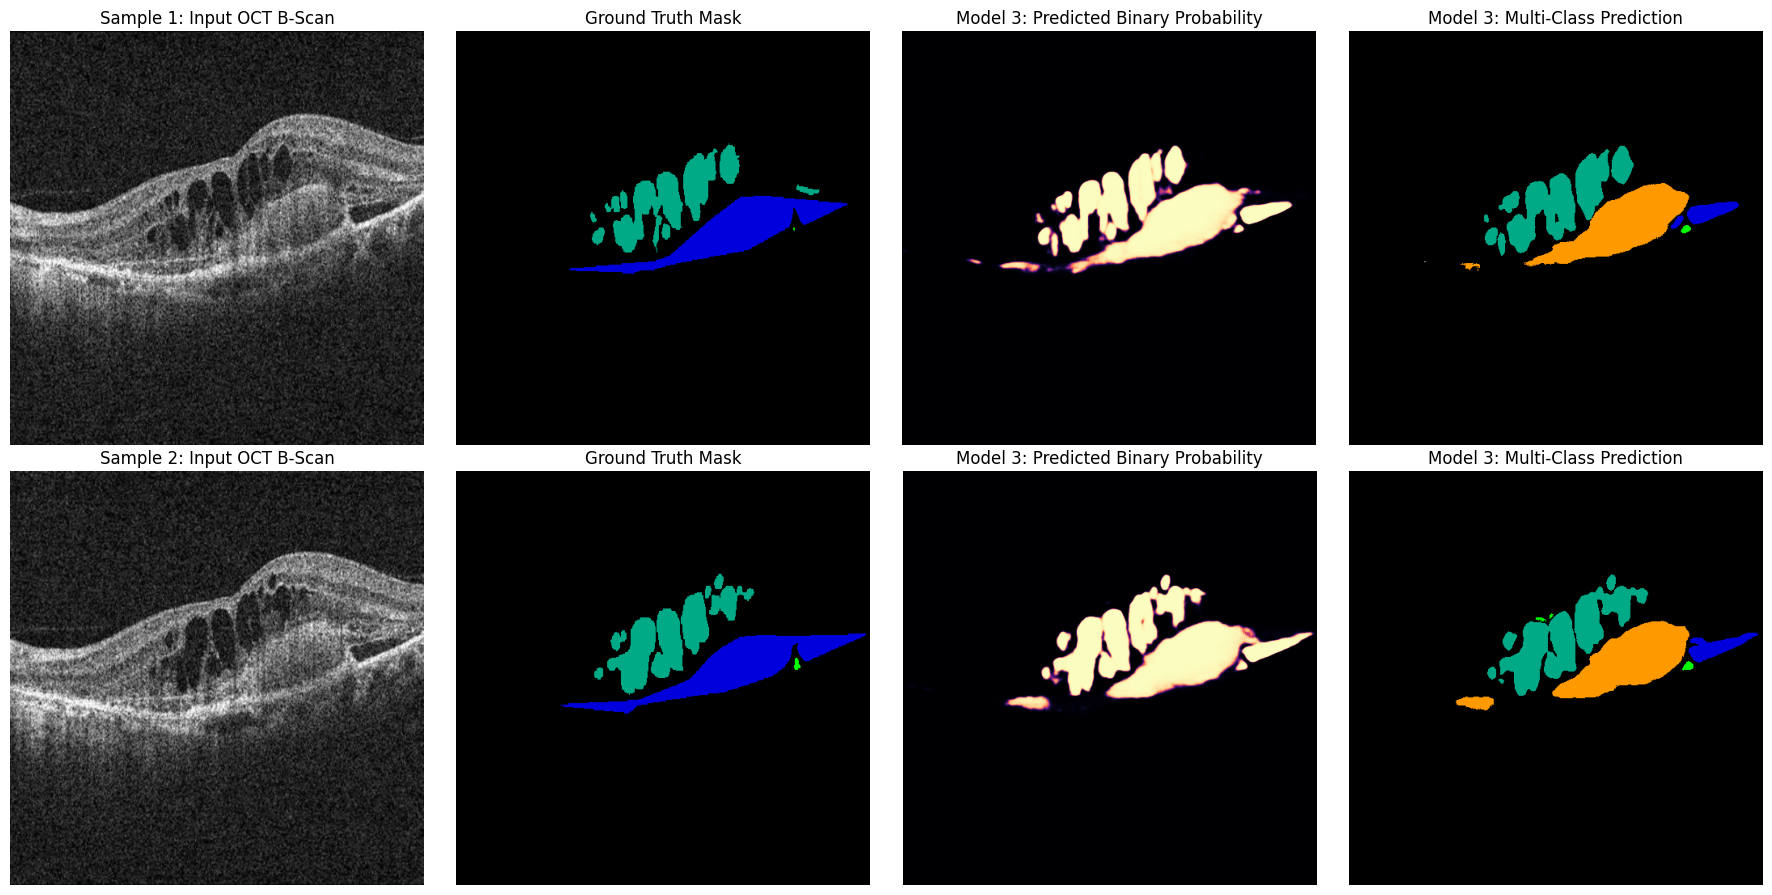

In [7]:
def visualize_model3_predictions(num_samples=2):
    CKPT_PATH = "best_unet_model3.pth"
    eval_model = Model3CrossSkipUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    eval_model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    eval_model.eval()

    val_imgs, val_targets, _ = next(iter(val_loader))
    val_imgs = val_imgs.to(device)

    with torch.no_grad():
        mc_logits, bin_logits = eval_model(val_imgs)
        pred_mc = torch.argmax(mc_logits, dim=1).cpu().numpy()
        pred_bin = torch.sigmoid(bin_logits).squeeze(1).cpu().numpy()

    fig, axs = plt.subplots(num_samples, 4, figsize=(18, 4.5 * num_samples))
    for i in range(num_samples):
        # 1. Raw OCT Scan
        axs[i, 0].imshow(val_imgs[i, 0].cpu().numpy(), cmap='gray')
        axs[i, 0].set_title(f"Sample {i+1}: Input OCT B-Scan")
        axs[i, 0].axis("off")

        # 2. Multi-Class Ground Truth
        axs[i, 1].imshow(val_targets[i].numpy(), cmap='nipy_spectral', vmin=0, vmax=5)
        axs[i, 1].set_title("Ground Truth Mask")
        axs[i, 1].axis("off")

        # 3. Model 3 Predicted Binary Lesion Map
        axs[i, 2].imshow(pred_bin[i], cmap='magma', vmin=0.0, vmax=1.0)
        axs[i, 2].set_title("Model 3: Predicted Binary Probability")
        axs[i, 2].axis("off")

        # 4. Model 3 Multi-Class Segmentation Output
        axs[i, 3].imshow(pred_mc[i], cmap='nipy_spectral', vmin=0, vmax=5)
        axs[i, 3].set_title("Model 3: Multi-Class Prediction")
        axs[i, 3].axis("off")

    plt.tight_layout()
    plt.show()

visualize_model3_predictions(num_samples=2)

## 7. Statistical Evaluation: 99% Bootstrapped Confidence Intervals & Per-Class Boxplots
Computes slice-level Dice Similarity Coefficients (DSC) and Intersection over Union (IoU) across the test cohort, calculates non-parametric 99% bootstrapped confidence intervals (2,000 resamples) for each biomarker, and generates per-class boxplots across all test scans to evaluate model variance and lesion-specific architectural trade-offs.

Directory 'processed_data/test/inputs' not found. Falling back to 'val' split.
Evaluating 703 images from split 'val' on device 'mps'...


Calculating Per-Image Metrics: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [01:23<00:00,  4.19it/s]
/var/folders/xg/slbv315n7nsgjg7ncb501lxc0000gn/T/ipykernel_35043/1865178393.py:159: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(
/var/folders/xg/slbv315n7nsgjg7ncb501lxc0000gn/T/ipykernel_35043/1865178393.py:159: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(



Saved per-image score distributions to 'model3_test_per_image_scores.csv'.

      WET AMD SEGMENTATION: BOOTSTRAPPED 99% CONFIDENCE INTERVALS (2000 RESAMPLES)
Biomarker / Class Metric  Observed Mean (%)  99% CI Lower (%)  99% CI Upper (%)     99% CI Range
              SRF    DSC              77.19             73.94             80.34 [73.94%, 80.34%]
              IRF    DSC              88.00             85.21             90.68 [85.21%, 90.68%]
              PED    DSC              69.53             65.90             72.94 [65.90%, 72.94%]
             SHRM    DSC              68.86             65.22             72.38 [65.22%, 72.38%]
            IS/OS    DSC              76.05             73.48             78.88 [73.48%, 78.88%]
             Mean    DSC              75.92             74.12             77.47 [74.12%, 77.47%]
              SRF    IoU              71.95             68.62             75.31 [68.62%, 75.31%]
              IRF    IoU              86.08             83.21   

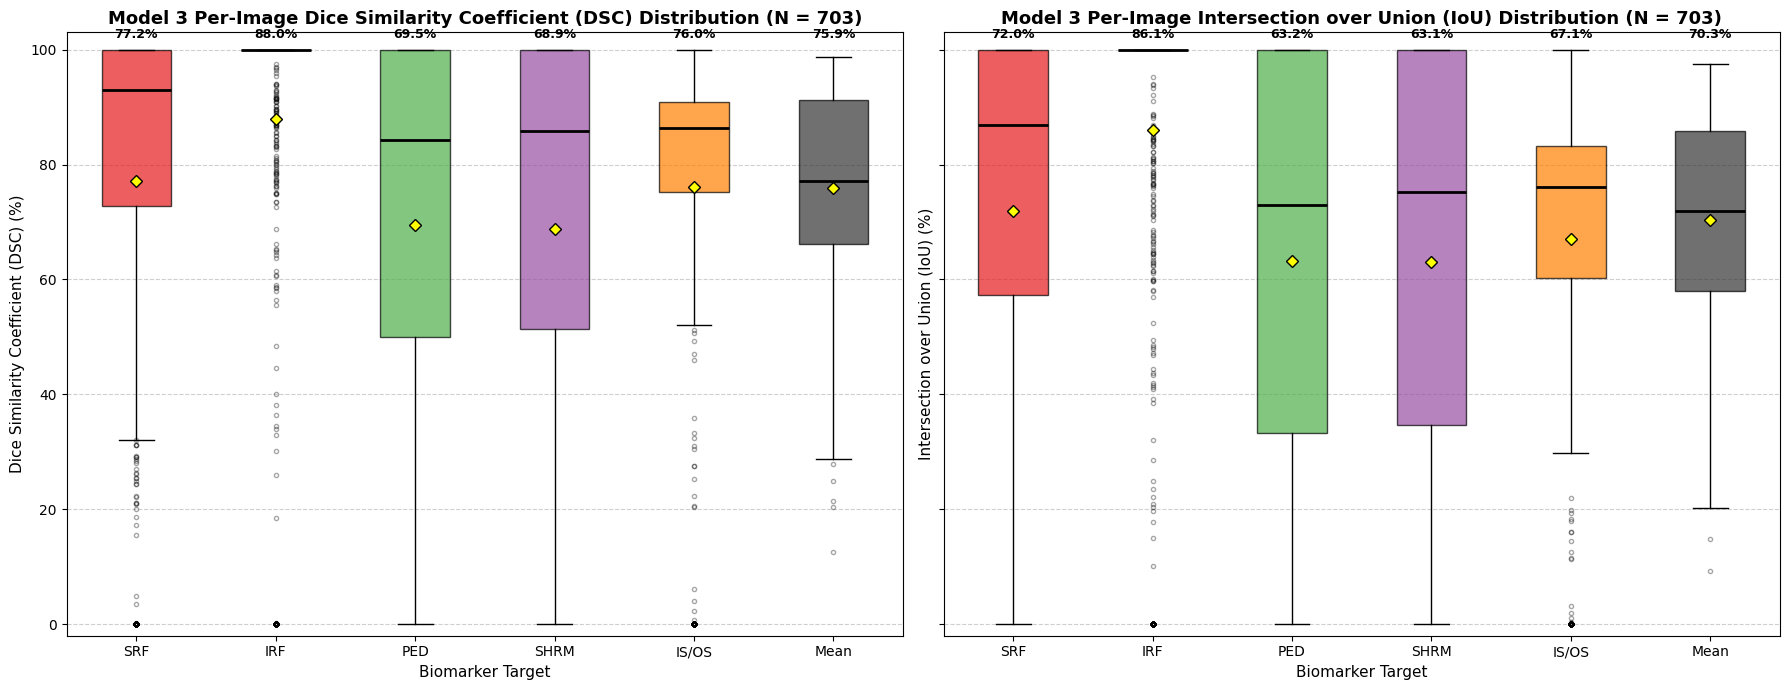

Saved visualization figure to 'model3_test_per_image_boxplots.png'.


In [8]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

def run_test_bootstrapping_and_profiling(
    checkpoint_path: str = "best_unet_model3.pth",
    test_split: str = "test",
    n_bootstraps: int = 2000,
    random_seed: int = 42,
    save_prefix: str = "model3_test"
):
    cleanup_memory()
    seed_everything(random_seed)

    # 1. Setup Test/Evaluation DataLoader
    test_dir = os.path.join(DATA_DIR, test_split, "inputs")
    eval_split = test_split if os.path.exists(test_dir) else "val"
    if eval_split != test_split:
        print(f"Directory '{test_dir}' not found. Falling back to '{eval_split}' split.")

    test_dataset = AMDDatasetModel3(DATA_DIR, split=eval_split, target_size=(512, 512), augment=False)
    test_loader = DataLoader(
        test_dataset,
        batch_size=VAL_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )
    print(f"Evaluating {len(test_dataset)} images from split '{eval_split}' on device '{device}'...")

    # 2. Load Model 3 Weights
    eval_model = Model3CrossSkipUNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Checkpoint not found at '{checkpoint_path}'.")
    eval_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    eval_model.eval()

    # 3. Compute Per-Image, Per-Class DSC & IoU
    biomarkers = ["SRF", "IRF", "PED", "SHRM", "IS/OS"]
    class_indices = {name: idx for idx, name in enumerate(biomarkers, start=1)}
    
    per_image_records = []
    image_counter = 0

    eps = 1e-7

    with torch.no_grad():
        for images, mc_targets, _ in tqdm(test_loader, desc="Calculating Per-Image Metrics"):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)

            mc_logits, _ = eval_model(images)
            preds = torch.argmax(mc_logits, dim=1)

            batch_size_cur = images.size(0)
            for b in range(batch_size_cur):
                pred_b = preds[b]
                target_b = mc_targets[b]

                row_data = {"image_idx": image_counter}
                dice_scores_per_class = []
                iou_scores_per_class = []

                for name, c in class_indices.items():
                    p_mask = (pred_b == c).float()
                    t_mask = (target_b == c).float()

                    p_sum = p_mask.sum().item()
                    t_sum = t_mask.sum().item()
                    inter = (p_mask * t_mask).sum().item()
                    union = p_sum + t_sum - inter

                    if (p_sum + t_sum) == 0:
                        # Both prediction and ground truth contain 0 pixels for this class
                        dsc = 1.0
                        iou = 1.0
                    else:
                        dsc = (2.0 * inter + eps) / (p_sum + t_sum + eps)
                        iou = (inter + eps) / (union + eps)

                    # Scale to percentage
                    dsc_pct = dsc * 100.0
                    iou_pct = iou * 100.0

                    row_data[f"{name}_DSC"] = dsc_pct
                    row_data[f"{name}_IoU"] = iou_pct
                    dice_scores_per_class.append(dsc_pct)
                    iou_scores_per_class.append(iou_pct)

                row_data["Mean_DSC"] = np.mean(dice_scores_per_class)
                row_data["Mean_IoU"] = np.mean(iou_scores_per_class)
                per_image_records.append(row_data)
                image_counter += 1

    df_per_image = pd.DataFrame(per_image_records)
    per_image_csv = f"{save_prefix}_per_image_scores.csv"
    df_per_image.to_csv(per_image_csv, index=False)
    print(f"\nSaved per-image score distributions to '{per_image_csv}'.")

    # 4. Bootstrap 99% Confidence Interval Calculation
    # 99% CI corresponds to the 0.5th and 99.5th percentiles
    rng = np.random.default_rng(random_seed)
    n_samples = len(df_per_image)
    metrics_to_eval = [f"{b}_DSC" for b in biomarkers] + ["Mean_DSC"] + \
                      [f"{b}_IoU" for b in biomarkers] + ["Mean_IoU"]

    ci_summary = []

    for metric_col in metrics_to_eval:
        values = df_per_image[metric_col].to_numpy()
        observed_mean = np.mean(values)

        # Vectorized bootstrapping
        boot_indices = rng.integers(0, n_samples, size=(n_bootstraps, n_samples))
        boot_means = np.mean(values[boot_indices], axis=1)

        ci_lower = np.percentile(boot_means, 0.5)
        ci_upper = np.percentile(boot_means, 99.5)

        class_name = metric_col.rsplit("_", 1)[0]
        metric_type = metric_col.rsplit("_", 1)[1]

        ci_summary.append({
            "Biomarker / Class": class_name,
            "Metric": metric_type,
            "Observed Mean (%)": round(observed_mean, 2),
            "99% CI Lower (%)": round(ci_lower, 2),
            "99% CI Upper (%)": round(ci_upper, 2),
            "99% CI Range": f"[{ci_lower:.2f}%, {ci_upper:.2f}%]"
        })

    df_ci = pd.DataFrame(ci_summary)
    ci_csv = f"{save_prefix}_bootstrapped_99_ci.csv"
    df_ci.to_csv(ci_csv, index=False)

    print("\n" + "=" * 90)
    print("      WET AMD SEGMENTATION: BOOTSTRAPPED 99% CONFIDENCE INTERVALS (2000 RESAMPLES)")
    print("=" * 90)
    print(df_ci.to_string(index=False))
    print(f"\nSaved 99% CI table to '{ci_csv}'.")

    # 5. Generate Per-Class Boxplots Across All Test Images
    plot_classes = biomarkers + ["Mean"]
    dsc_cols = [f"{c}_DSC" for c in plot_classes]
    iou_cols = [f"{c}_IoU" for c in plot_classes]

    fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
    palette = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#333333"]

    for ax, cols, title in zip(axes, [dsc_cols, iou_cols], ["Dice Similarity Coefficient (DSC)", "Intersection over Union (IoU)"]):
        box_data = [df_per_image[col].values for col in cols]
        
        box = ax.boxplot(
            box_data,
            patch_artist=True,
            labels=plot_classes,
            showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "yellow", "markeredgecolor": "black", "markersize": 6},
            medianprops={"color": "black", "linewidth": 2},
            flierprops={"marker": "o", "color": "gray", "alpha": 0.35, "markersize": 3}
        )

        for patch, color in zip(box["boxes"], palette):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        ax.set_title(f"Model 3 Per-Image {title} Distribution (N = {n_samples})", fontsize=13, fontweight="bold")
        ax.set_ylabel(f"{title} (%)", fontsize=11)
        ax.set_xlabel("Biomarker Target", fontsize=11)
        ax.set_ylim(-2, 103)
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        # Annotate mean values above each category
        means = [np.mean(vals) for vals in box_data]
        for idx, mean_val in enumerate(means, start=1):
            ax.text(
                idx, 101.5, f"{mean_val:.1f}%",
                ha="center", va="bottom", fontsize=9, fontweight="bold"
            )

    plt.tight_layout()
    plot_path = f"{save_prefix}_per_image_boxplots.png"
    plt.savefig(plot_path, dpi=300)
    plt.show()
    print(f"Saved visualization figure to '{plot_path}'.")

    cleanup_memory()

# Execute validation and statistical analysis
run_test_bootstrapping_and_profiling(
    checkpoint_path="best_unet_model3.pth",
    test_split="test",
    n_bootstraps=2000,
    random_seed=42
)